In [1]:
# 1. Imports
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import sys
import subprocess
try:
    import tqdm
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'tqdm'])
from tqdm import tqdm
import json
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.amp import autocast, GradScaler
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
# Windows: No need to set matplotlib backend for headless mode

In [2]:
# 2. Import models and losses
from pathlib import Path
import importlib

# Ensure repo root is on sys.path so `import src...` works
cwd = Path.cwd().resolve()
repo_root = next((p for p in [cwd, *cwd.parents] if (p / 'src').exists()), cwd)
if str(repo_root) not in sys.path:
	sys.path.insert(0, str(repo_root))

import src.models.unet_inpaint as unet_mod
import src.models.patchgan_discriminator as disc_mod
import src.models.losses as loss_mod
importlib.reload(unet_mod)
importlib.reload(disc_mod)
importlib.reload(loss_mod)

UNet = unet_mod.UNet
PatchGANDiscriminator = disc_mod.PatchGANDiscriminator
GANLoss = loss_mod.GANLoss
PerceptualLoss = loss_mod.PerceptualLoss
SSIMLoss = loss_mod.SSIMLoss
print(f'Generator, Discriminator, and loss modules loaded. repo_root={repo_root}')

Generator, Discriminator, and loss modules loaded. repo_root=C:\Users\henry\Desktop\isef2026


In [3]:
# 3. CONFIGURATION — edit these to switch datasets / hyperparams
# Data paths (relative to repo root)
DATA_ROOT = os.path.join(str(repo_root), 'data', 'gan_a', 'phase_1', 'experiment')
TRAIN_IMAGE_DIR       = os.path.join(DATA_ROOT, 'train', 'image')
TRAIN_MASK_DIR        = os.path.join(DATA_ROOT, 'train', 'mask')
TRAIN_BINARY_MASK_DIR = os.path.join(DATA_ROOT, 'train', 'binary_mask_processed')
TEST_IMAGE_DIR        = os.path.join(DATA_ROOT, 'test', 'image')
TEST_MASK_DIR         = os.path.join(DATA_ROOT, 'test', 'mask')
TEST_BINARY_MASK_DIR  = os.path.join(DATA_ROOT, 'test', 'binary_mask_processed')
# Output directories
CHECKPOINT_DIR   = os.path.join(str(repo_root), 'src', 'models', 'checkpoints')
LOG_DIR          = os.path.join(str(repo_root), 'results', 'logs')
SAMPLE_DIR       = os.path.join(str(repo_root), 'results', 'figures', 'training_samples')
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(SAMPLE_DIR, exist_ok=True)
# Hyperparameters
BATCH_SIZE    = 16
NUM_EPOCHS    = 200
IMAGE_SIZE    = 512
SAVE_EVERY    = 10
SAMPLE_EVERY  = 10
NUM_WORKERS   = 0
G_LEARNING_RATE = 1e-4
G_FEATURES      = [64, 128, 256, 512]
D_LEARNING_RATE  = 2e-4
D_BASE_FEATURES  = 64
D_N_LAYERS       = 3
LAMBDA_L1         = 100.0
LAMBDA_SSIM       = 10.0
LAMBDA_PERCEPTUAL = 10.0
LAMBDA_ADV        = 1.0
GAN_MODE          = 'lsgan'
device = torch.device('cuda')
print(f'Device: {device}')

Device: cuda


In [5]:
# 4. Dataset class — loads paired (image, binary_mask, target) and resizes to IMAGE_SIZE
class PairedInpaintDataset(Dataset):
    """Loads matched (masked_image, binary_lesion_mask, target_image) triplets for inpainting.
    Returns a 4-channel input (RGB + binary lesion mask) and 3-channel target (RGB)."""
    def __init__(self, image_folder, mask_folder, binary_mask_folder, image_size=512):
        self.images       = sorted([f for f in os.listdir(image_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        self.masks        = sorted([f for f in os.listdir(mask_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        self.binary_masks = sorted([f for f in os.listdir(binary_mask_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        assert self.images == self.masks == self.binary_masks, 'Image, mask, and binary_mask filenames must match!'
        self.image_folder       = image_folder
        self.mask_folder        = mask_folder
        self.binary_mask_folder = binary_mask_folder
        self.rgb_transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
        ])
        self.gray_transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),  # produces [1, H, W] for grayscale
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        img         = Image.open(os.path.join(self.image_folder, self.images[index])).convert('RGB')
        mask        = Image.open(os.path.join(self.mask_folder, self.masks[index])).convert('RGB')
        binary_mask = Image.open(os.path.join(self.binary_mask_folder, self.binary_masks[index])).convert('L')
        img_t         = self.rgb_transform(img)          # [3, H, W]
        mask_t        = self.rgb_transform(mask)          # [3, H, W]
        binary_mask_t = self.gray_transform(binary_mask)  # [1, H, W]
        # Concatenate RGB + binary lesion mask -> [4, H, W]
        input_4ch = torch.cat([img_t, binary_mask_t], dim=0)
        return input_4ch, mask_t, self.images[index]

# Create datasets and dataloaders
train_dataset = PairedInpaintDataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, TRAIN_BINARY_MASK_DIR, IMAGE_SIZE)
test_dataset  = PairedInpaintDataset(TEST_IMAGE_DIR, TEST_MASK_DIR, TEST_BINARY_MASK_DIR, IMAGE_SIZE)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
print(f'Train samples: {len(train_dataset)} | Test samples: {len(test_dataset)}')

Train samples: 1368 | Test samples: 38


In [6]:
# 5. Instantiate model and losses
netG = UNet(in_channels=4, out_channels=3, features=G_FEATURES).to(device)
criterion_l1 = nn.L1Loss().to(device)
criterion_ssim = SSIMLoss().to(device)
criterion_perc = PerceptualLoss().to(device)
print('Model and loss functions instantiated.')

Model and loss functions instantiated.


# GAN-A Model Testing Notebook
This notebook is standalone and includes all necessary setup to test your trained GAN-A model.

In [7]:
# 8. (Optional) Load a specific checkpoint for testing (with debug)
ckpt_path = os.path.join(CHECKPOINT_DIR, 'ganA_epoch145.pth')
print(f"Attempting to load checkpoint: {ckpt_path}")
if not os.path.exists(ckpt_path):
    raise FileNotFoundError(f"Checkpoint file not found: {ckpt_path}")
try:
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    netG.load_state_dict(ckpt['netG_state_dict'])
    print(f"Loaded checkpoint from epoch {ckpt.get('epoch', 'unknown')}")
except Exception as e:
    print(f"Error loading checkpoint: {e}")
    import traceback; traceback.print_exc()

Attempting to load checkpoint: C:\Users\henry\Desktop\isef2026\src\models\checkpoints\ganA_epoch145.pth
Loaded checkpoint from epoch 145


Starting test image evaluation...
TEST_INDEX: 25
Loaded test sample: healthy_0230.png
input_4ch shape: torch.Size([4, 512, 512])
input_4ch dtype: torch.float32
Model device: cuda:0
Model forward pass complete.
Tensor conversion complete.
Metrics computed.


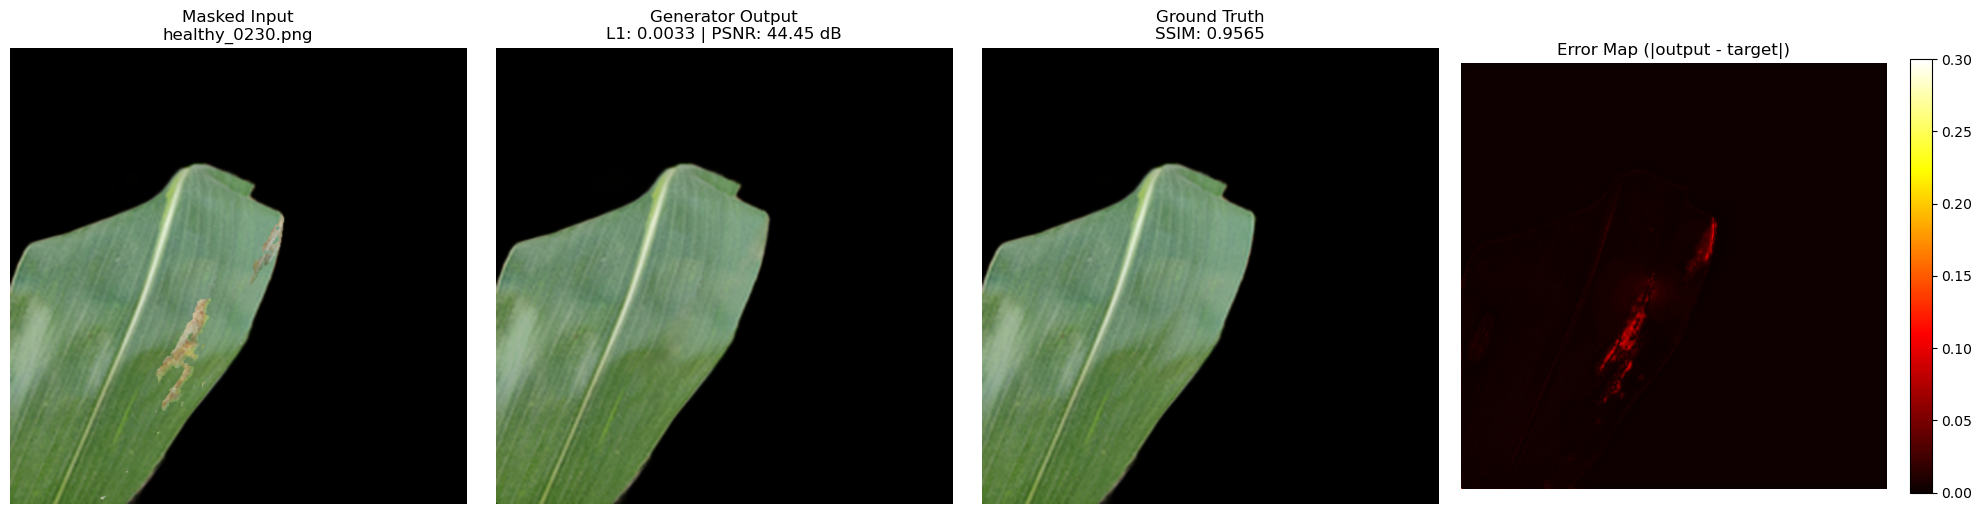

Plotting complete.


In [8]:
TEST_INDEX = 25 # <-- Change this to test any image (0 to len-1)

print("Starting test image evaluation...")
try:
    print(f"TEST_INDEX: {TEST_INDEX}")
    torch.cuda.empty_cache()
    netG.eval()
    input_4ch, target_tensor, fname = test_dataset[TEST_INDEX]
    print("Loaded test sample:", fname)
    print("input_4ch shape:", input_4ch.shape)
    print("input_4ch dtype:", input_4ch.dtype)
    print("Model device:", next(netG.parameters()).device)
    with torch.no_grad():
        output = netG(input_4ch.unsqueeze(0).to(device))
    print("Model forward pass complete.")
    output_np = output.squeeze(0).cpu().permute(1, 2, 0).clamp(0, 1).numpy()
    input_np = input_4ch[:3].permute(1, 2, 0).numpy()  # show only RGB channels
    target_np = target_tensor.permute(1, 2, 0).numpy()
    print("Tensor conversion complete.")

    # Compute metrics
    l1_err = np.mean(np.abs(output_np - target_np))
    mse = np.mean((output_np - target_np) ** 2)
    psnr = 10 * np.log10(1.0 / (mse + 1e-10))
    with torch.no_grad():
        ssim_val = criterion_ssim.ssim_value(output, target_tensor.unsqueeze(0).to(output.device)).item()
    print("Metrics computed.")
    del output

    # Difference map (amplified for visibility)
    diff_map = np.mean(np.abs(output_np - target_np), axis=2)

    fig, axs = plt.subplots(1, 4, figsize=(20, 5))
    axs[0].imshow(input_np)
    axs[0].set_title(f'Masked Input\n{fname}')
    axs[0].axis('off')
    axs[1].imshow(output_np)
    axs[1].set_title(f'Generator Output\nL1: {l1_err:.4f} | PSNR: {psnr:.2f} dB')
    axs[1].axis('off')
    axs[2].imshow(target_np)
    axs[2].set_title(f'Ground Truth\nSSIM: {ssim_val:.4f}')
    axs[2].axis('off')
    im = axs[3].imshow(diff_map, cmap='hot', vmin=0, vmax=0.3)
    axs[3].set_title('Error Map (|output - target|)')
    axs[3].axis('off')
    plt.colorbar(im, ax=axs[3], fraction=0.046)
    plt.tight_layout()
    # plt.savefig(os.path.join(SAMPLE_DIR, f'test_sample_{TEST_INDEX}.png'), dpi=150, bbox_inches='tight')
    plt.show()
    print("Plotting complete.")
except Exception as e:
    import traceback
    print("Error during test image evaluation:", e)
    traceback.print_exc()

IntSlider(value=1, description='Index:', max=263, min=1)

Output()

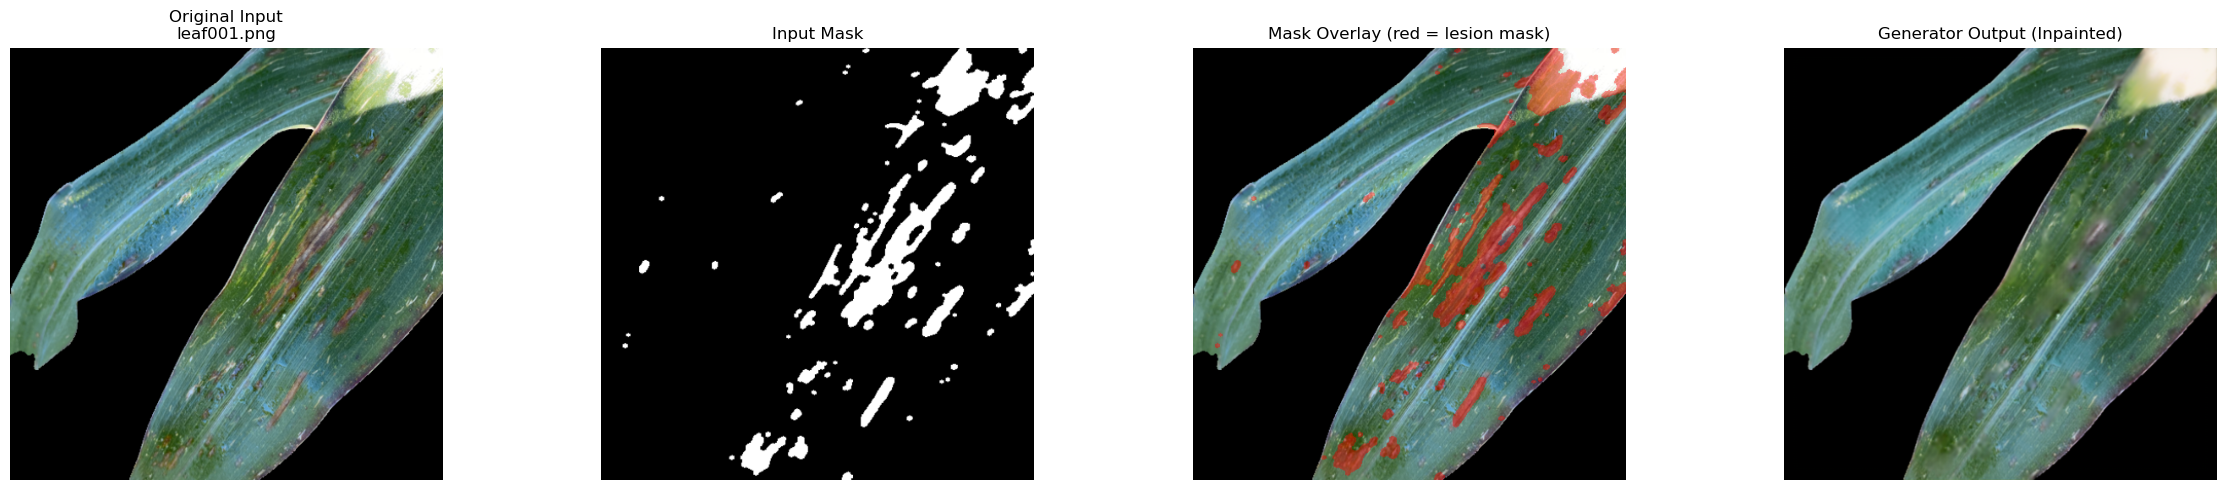

In [9]:
# 10. Interactive test: drag slider to view different images quickly
import ipywidgets as widgets
from IPython.display import display, clear_output

def show_test_image(index):
    index_str = str(index).zfill(3)  # always 3 digits, e.g. 001, 010, 123
    TEST_IMAGE_PATH = os.path.join(str(repo_root), 'data', 'diseased', 'gls', f'leaf{index_str}.png')
    TEST_BINARY_MASK_PATH = os.path.join(str(repo_root), 'data', 'masks', 'lesion_real_expanded', 'gls', f'mask_leaf{index_str}.png')
    if not os.path.exists(TEST_IMAGE_PATH) or not os.path.exists(TEST_BINARY_MASK_PATH):
        print(f"Image or mask not found for index {index_str}")
        return
    torch.cuda.empty_cache()
    netG.eval()
    img = Image.open(TEST_IMAGE_PATH).convert('RGB')
    binary_mask = Image.open(TEST_BINARY_MASK_PATH).convert('L')
    tfm_rgb  = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()])
    tfm_gray = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()])
    img_t         = tfm_rgb(img)
    binary_mask_t = tfm_gray(binary_mask)
    input_4ch = torch.cat([img_t, binary_mask_t], dim=0)  # [4, H, W]
    with torch.no_grad():
        output = netG(input_4ch.unsqueeze(0).to(device))
    output_np = output.squeeze(0).cpu().permute(1, 2, 0).clamp(0, 1).numpy()
    input_np  = img_t.permute(1, 2, 0).numpy()
    mask_np   = binary_mask_t.squeeze(0).numpy()
    del output

    # Build red overlay
    overlay = input_np.copy()
    overlay[mask_np > 0.5] = [1, 0, 0]
    blended = input_np * 0.6 + overlay * 0.4

    # Show input, mask, overlay, and output
    fig, axs = plt.subplots(1, 4, figsize=(24, 5))
    axs[0].imshow(input_np)
    axs[0].set_title(f'Original Input\nleaf{index_str}.png')
    axs[0].axis('off')
    axs[1].imshow(mask_np, cmap='gray', vmin=0, vmax=1)
    axs[1].set_title('Input Mask')
    axs[1].axis('off')
    axs[2].imshow(blended)
    axs[2].set_title('Mask Overlay (red = lesion mask)')
    axs[2].axis('off')
    axs[3].imshow(output_np)
    axs[3].set_title('Generator Output (Inpainted)')
    axs[3].axis('off')
    plt.tight_layout()
    plt.show()

# Find the available indices automatically
image_dir = os.path.join(str(repo_root), 'data', 'diseased', 'gls')
image_files = sorted([f for f in os.listdir(image_dir) if f.startswith('leaf') and f.endswith('.png')])
def extract_index(fname):
    # expects fname like leaf0001.png
    return int(fname[4:-4]) if fname[4:-4].isdigit() else None
indices = [extract_index(f) for f in image_files if extract_index(f) is not None]
if indices:
    min_idx = min(indices)
    max_idx = max(indices)
else:
    min_idx = 1
    max_idx = 1

slider = widgets.IntSlider(value=min_idx, min=min_idx, max=max_idx, step=1, description='Index:')
out = widgets.Output()

def on_value_change(change):
    with out:
        clear_output(wait=True)
        show_test_image(change['new'])

slider.observe(on_value_change, names='value')
display(slider, out)
show_test_image(slider.value)

Found 1368 matched image/binary_mask/target triplets.


IntSlider(value=0, continuous_update=False, description='Pair:', max=1367)

Output()

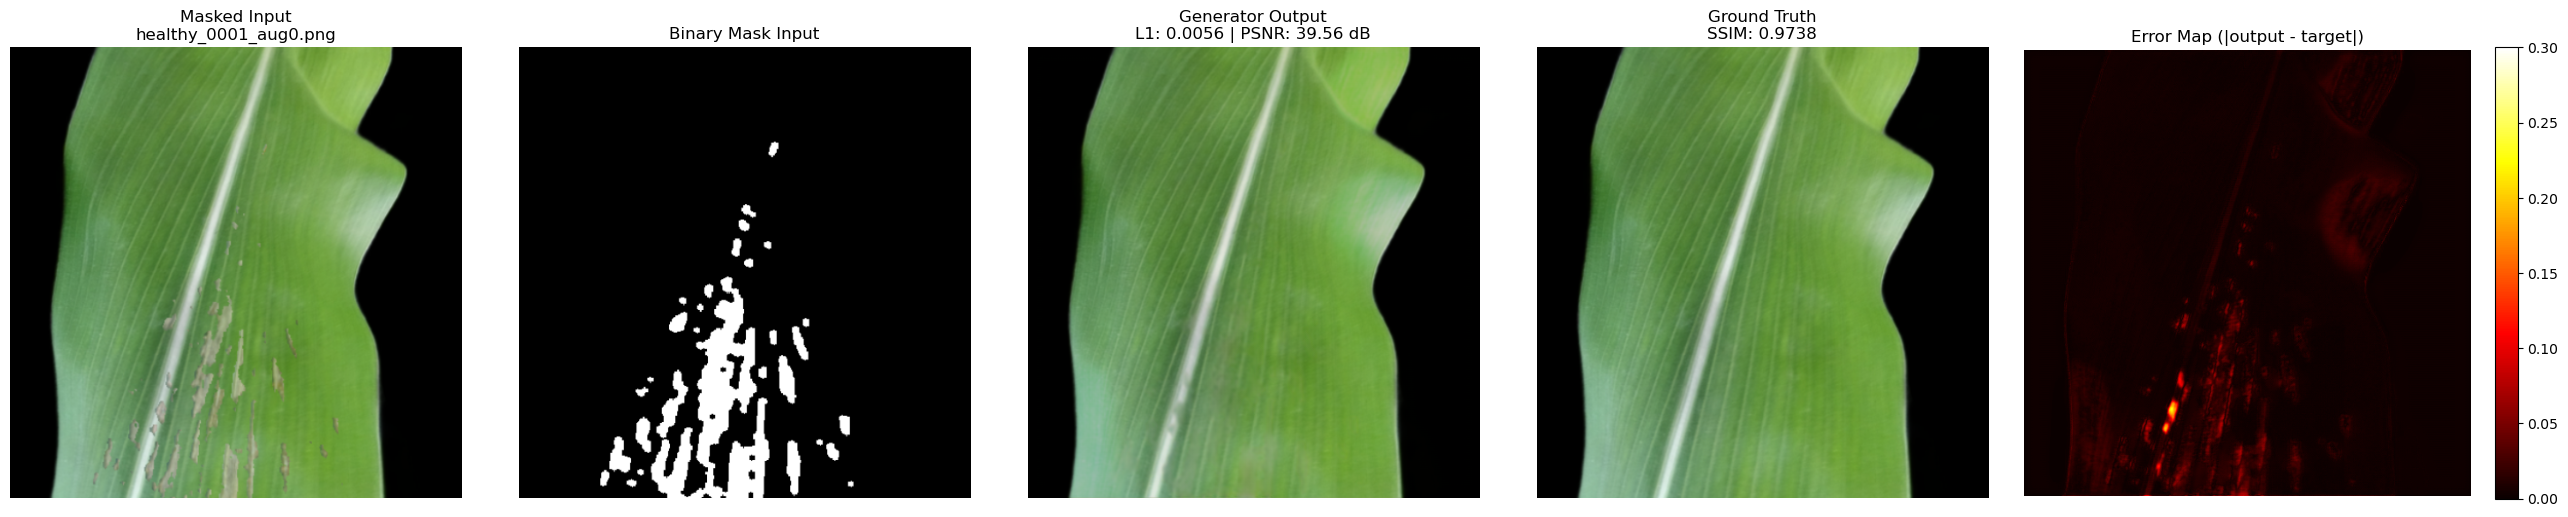

In [9]:
# 11. Interactive train inference: image + binary_mask -> GAN output (eval-style view)
import ipywidgets as widgets
from IPython.display import display, clear_output

# Use configured train folders from Cell 3
image_dir = TRAIN_IMAGE_DIR
binary_mask_dir = TRAIN_BINARY_MASK_DIR
target_dir = TRAIN_MASK_DIR

image_files = sorted([f for f in os.listdir(image_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
binary_mask_files = sorted([f for f in os.listdir(binary_mask_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
target_files = sorted([f for f in os.listdir(target_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

# Pair by exact filename intersection (supports names containing 'aug')
common_files = sorted(set(image_files).intersection(binary_mask_files).intersection(target_files))
if not common_files:
    raise RuntimeError(
        f'No matching filenames found across:\n- {image_dir}\n- {binary_mask_dir}\n- {target_dir}\n'
        'Ensure image, binary_mask, and target folders share identical filenames.'
    )

print(f'Found {len(common_files)} matched image/binary_mask/target triplets.')

tfm_rgb = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])
tfm_gray = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

def show_train_inference(pair_idx):
    fname = common_files[pair_idx]
    image_path = os.path.join(image_dir, fname)
    binary_mask_path = os.path.join(binary_mask_dir, fname)
    target_path = os.path.join(target_dir, fname)

    img = Image.open(image_path).convert('RGB')
    binary_mask = Image.open(binary_mask_path).convert('L')
    target = Image.open(target_path).convert('RGB')

    img_t = tfm_rgb(img)
    binary_mask_t = tfm_gray(binary_mask)
    target_t = tfm_rgb(target)

    input_4ch = torch.cat([img_t, binary_mask_t], dim=0)  # [4, H, W]

    netG.eval()
    with torch.no_grad():
        output = netG(input_4ch.unsqueeze(0).to(device))

    output_np = output.squeeze(0).cpu().permute(1, 2, 0).clamp(0, 1).numpy()
    input_np = img_t.permute(1, 2, 0).numpy()
    binary_mask_np = binary_mask_t.squeeze(0).numpy()
    target_np = target_t.permute(1, 2, 0).numpy()

    # Metrics
    l1_err = np.mean(np.abs(output_np - target_np))
    mse = np.mean((output_np - target_np) ** 2)
    psnr = 10 * np.log10(1.0 / (mse + 1e-10))
    with torch.no_grad():
        ssim_val = criterion_ssim.ssim_value(output, target_t.unsqueeze(0).to(device)).item()

    # Difference map (amplified for visibility)
    diff_map = np.mean(np.abs(output_np - target_np), axis=2)

    fig, axs = plt.subplots(1, 5, figsize=(26, 5))
    axs[0].imshow(input_np)
    axs[0].set_title(f'Masked Input\n{fname}')
    axs[0].axis('off')

    axs[1].imshow(binary_mask_np, cmap='gray', vmin=0, vmax=1)
    axs[1].set_title('Binary Mask Input')
    axs[1].axis('off')

    axs[2].imshow(output_np)
    axs[2].set_title(f'Generator Output\nL1: {l1_err:.4f} | PSNR: {psnr:.2f} dB')
    axs[2].axis('off')

    axs[3].imshow(target_np)
    axs[3].set_title(f'Ground Truth\nSSIM: {ssim_val:.4f}')
    axs[3].axis('off')

    im = axs[4].imshow(diff_map, cmap='hot', vmin=0, vmax=0.3)
    axs[4].set_title('Error Map (|output - target|)')
    axs[4].axis('off')
    plt.colorbar(im, ax=axs[4], fraction=0.046)

    plt.tight_layout()
    plt.show()

slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(common_files) - 1,
    step=1,
    description='Pair:',
    continuous_update=False,
    readout=True,
    readout_format='d',
)
out = widgets.Output()

def on_value_change(change):
    with out:
        clear_output(wait=True)
        show_train_inference(change['new'])

slider.observe(on_value_change, names='value')
display(slider, out)
show_train_inference(slider.value)

In [10]:
# 12. Evaluate on FULL test set - average + per-image L1, SSIM, PSNR
import csv

torch.cuda.empty_cache()
netG.eval()
test_l1 = 0.0
test_ssim = 0.0
test_psnr = 0.0
n_test = 0

# Per-image metrics for statistical testing
test_metrics = []  # [{'filename', 'l1', 'ssim', 'psnr'}]

with torch.no_grad():
    for input_4ch, target, fname in tqdm(test_loader, desc='Evaluating test set'):
        input_4ch = input_4ch.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)
        out = netG(input_4ch)

        l1_val = criterion_l1(out, target).item()
        ssim_val = criterion_ssim.ssim_value(out, target).item()
        mse_val = torch.mean((out - target) ** 2).item()
        psnr_val = 10 * np.log10(1.0 / (mse_val + 1e-10))

        test_l1 += l1_val
        test_ssim += ssim_val
        test_psnr += psnr_val

        test_metrics.append({
            'filename': fname[0],
            'l1': l1_val,
            'ssim': ssim_val,
            'psnr': psnr_val,
        })

        n_test += 1
        del out

avg_l1 = test_l1 / max(n_test, 1)
avg_ssim = test_ssim / max(n_test, 1)
avg_psnr = test_psnr / max(n_test, 1)

# Arrays ready for t-tests
test_ssim_scores = np.array([r['ssim'] for r in test_metrics], dtype=np.float64)
test_psnr_scores = np.array([r['psnr'] for r in test_metrics], dtype=np.float64)

print('=' * 50)
print('FULL TEST SET EVALUATION')
print('=' * 50)
print(f'  Average L1 Loss:  {avg_l1:.6f}')
print(f'  Average SSIM:     {avg_ssim:.6f}')
print(f'  Average PSNR:     {avg_psnr:.2f} dB')
print('=' * 50)

# Save per-image metrics for external stats workflows
metrics_csv = os.path.join(LOG_DIR, 'ganA_test_per_image_metrics.csv')
with open(metrics_csv, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=['filename', 'l1', 'ssim', 'psnr'])
    writer.writeheader()
    writer.writerows(test_metrics)

print(f'Per-image metrics saved: {metrics_csv}')
print(f'Num test images: {len(test_metrics)}')
print('Variables available for t-tests: test_ssim_scores, test_psnr_scores')

Evaluating test set: 100%|██████████| 38/38 [00:03<00:00, 11.89it/s]

FULL TEST SET EVALUATION
  Average L1 Loss:  0.004705
  Average SSIM:     0.957928
  Average PSNR:     41.42 dB
Per-image metrics saved: C:\Users\henry\Desktop\isef2026\results\logs\ganA_test_per_image_metrics.csv
Num test images: 38
Variables available for t-tests: test_ssim_scores, test_psnr_scores


In [14]:
# 13. Batch export generator outputs from ONE image folder + ONE mask folder
from pathlib import Path
import re

# Set exactly two folders here:
IMAGE_FOLDER = os.path.join(str(repo_root), 'data', 'diseased', 'gls')
MASK_FOLDER = os.path.join(str(repo_root), 'data', 'masks', 'lesion_real_expanded', 'gls')

output_dir = Path(repo_root) / 'data' / 'synthetic' / 'images' / 'healthy'
output_dir.mkdir(parents=True, exist_ok=True)

image_dir = Path(IMAGE_FOLDER)
mask_dir = Path(MASK_FOLDER)

if not image_dir.exists():
    raise FileNotFoundError(f'Image folder not found: {image_dir}')
if not mask_dir.exists():
    raise FileNotFoundError(f'Mask folder not found: {mask_dir}')

tfm_rgb = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])
tfm_gray = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

valid_exts = {'.png', '.jpg', '.jpeg'}

def extract_index(name):
    # Supports names like leaf_001.png, leaf001.png, mask_leaf001.png
    stem = Path(name).stem.lower()
    m = re.search(r'(\d+)$', stem)
    return int(m.group(1)) if m else None

image_files = sorted([
    p.name for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() in valid_exts
])
mask_files = sorted([
    p.name for p in mask_dir.iterdir()
    if p.is_file() and p.suffix.lower() in valid_exts
])

image_by_idx = {}
for fname in image_files:
    idx = extract_index(fname)
    if idx is not None and idx not in image_by_idx:
        image_by_idx[idx] = fname

mask_by_idx = {}
for fname in mask_files:
    idx = extract_index(fname)
    if idx is not None and idx not in mask_by_idx:
        mask_by_idx[idx] = fname

common_indices = sorted(set(image_by_idx).intersection(mask_by_idx))
if not common_indices:
    raise RuntimeError(
        f'No matched numeric indices found across:\n- {image_dir}\n- {mask_dir}'
    )

print(f'Processing {len(common_indices)} matched pairs by index')
saved_count = 0

netG.eval()
with torch.no_grad():
    for idx in tqdm(common_indices, desc='Exporting outputs'):
        image_name = image_by_idx[idx]
        mask_name = mask_by_idx[idx]

        img = Image.open(image_dir / image_name).convert('RGB')
        binary_mask = Image.open(mask_dir / mask_name).convert('L')

        img_t = tfm_rgb(img)
        binary_mask_t = tfm_gray(binary_mask)
        input_4ch = torch.cat([img_t, binary_mask_t], dim=0)

        output = netG(input_4ch.unsqueeze(0).to(device))
        output_np = output.squeeze(0).cpu().permute(1, 2, 0).clamp(0, 1).numpy()
        output_img = Image.fromarray((output_np * 255).astype(np.uint8))

        # Save using the image filename style (e.g., leaf_001.png).
        output_img.save(output_dir / image_name)
        saved_count += 1
        del output

print(f'Export complete. Saved {saved_count} generated images to: {output_dir}')

Processing 263 matched pairs by index


Exporting outputs: 100%|██████████| 263/263 [00:26<00:00,  9.76it/s]

Export complete. Saved 263 generated images to: C:\Users\henry\Desktop\isef2026\data\synthetic\images\healthy
